# Artificial Intelligence in Health Care - Exercise 1
## Readmission Risk from Structured Clinical Data

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel dieser Übung ist es das Wiederaufnahmerisiko anhand des Diabetes-Datensatzes zu untersuchen und eine logistische Regression mit einem neuronalen Netz zu vergleichen. Für die Berechechnung des Wiederaufnahemrisikos werden alle bis zu Entlassung verfügbaren Patientendaten miteinbezogen.

### 1 Problem Formulation [1.5P]  

1. Die klinische Fragestellung: 
--> Trifft ein neuronales Netz oder eine logistische Regression bessere Vorhersagen über die Wiederaufnahme eines Patienten innerhalb von 30 Tagen?  <font color='red'>(unter Berücksichtigung aller verfügbaren Patientendaten?)</font>
--> Lässt sich anhand der bis zur Entlassung verfügbaren klinischen Daten vorhersagen, ob ein Patient innerhalb von 30 Tagen erneut stationär aufgenommen wird?


2. **Zielvariable:** Die Zielvariable ist eine erneute stationäre Aufnahme innerhalb von 30 Tagen nach der Entlassung. Die ursprüngliche Variable 'readmitted' besitzt die Ausprägungen <30, >30 und NO. Wir kodieren <30 als 1 und fassen >30 sowie NO zur Klasse 0 zusammen`. Da der Fokus auf frühen Wiederaufnahmen liegt macht diese Binarisierung am meisten Sinn, da Fälle ohne einer oder mit einer späten Wiederaufnahme nicht zum Zielereignis passen.

3. **Untersuchte Population:** Zur Ermittlung der ein- bzw ausgeschlossenen Fälle wurde die Entlassungsart (discharge_disposition_id) herangezogen. Die zugehörigen Kategorien und ihre Beschreibungen sind in IDS_mapping.csv dokumentiert. Folgende Aufenthalte wurden ausgeschlossen:

    * Personen die verstorben sind (discharge_disposition_id = 11, 19, 20, 21): Eine Wiederaufnahme ist nicht möglich.  
    * Personen die keinen eindeutig abgeschlossenen Aufenthalt haben (discharge_disposition_id = 9, 12): Es ist nicht klar ob eine Entlassung stattgefunden hat. Damit fehlt ein klarer Ausgangspunkt für die Betrachtung einer Wiederaufnahme innerhalb von 30 Tagen.
    *  Personen die in ein Hospiz oder ähnliches entlassen wurden (discharge_disposition_id = 13, 14): einerseits ist die Wahrscheinlichkeit ist höher dass diese Personen zeitnahe versterben andererseits bekommen diese eine intensivere Betreuung.
    * Personen deren Enlassungsart unklar oder nicht dokumentiert ist (discharge_disposition_id = 18, 25, 26): Bei diesen Aufenthalten lässt sich nicht zuverlässig beurteilen, ob die festgelegten Einschlusskriterien erfüllt sind.

4. Zielgruppe (Anwender) sowie eine konkrete Entscheidung, die mithilfe der Vorhersage unterstützt werden soll.  
**Anwender:** Pflegepersonen im Entlassungsmanagement
**Unterstützte Entscheidung:** Ist für einen Patienten eine intensivere Nachbetreuung notwendig?
**Begründung:** Das entwickelte Modell soll Pflegepersonen im Rahmen des Entlassungsmanagements unterstützen, Patient:innen mit einem erhöhten Risiko für eine Wiederaufnahme innerhalb von 30 Tagen zu identifizieren. Auf dieser Grundlage können sie bereits vor der Entlassung prüfen, ob zusätzliche Maßnahmen sinnvoll sind, beispielsweise frühere oder häufigere Nachkontrolltermine. Die Vorhersage dient dabei als Ergänzung zur pflegerischen und ärztlichen Einschätzung.

### 2 Data Exploration [2.5P]
Zunächst verschaffen wir uns einen Überblick über die vorhandenen Daten. Dazu untersuchen wir die Datenstruktur, insbesondere die Anzahl der Krankenhausaufenthalte und Spalten sowie die Datentypen der Merkmale. Anschließend betrachten wir die Verteilungen numerischer und kategorialer Merkmale und prüfen auffällige Werte sowie mögliche Ausreißer. Abschließend bestimmen wir die absoluten und relativen Häufigkeiten der Wiederaufnahmekategorien (<30, >30, NO) sowie der daraus abgeleiteten binären Zielvariable.

#### 2a Struktur, Verteilung und Klassenverteilung

In [60]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [61]:
# Datenstruktur untersuchen
# Datensatz importieren
diabetes_orig = pd.read_csv("diabetic_data.csv", na_values=["?"]) # ? bedeutet fehlende Werte

# Größe des Datensatzes
print(f"Der Datensatz hat {diabetes_orig.shape[0]} Zeilen und {diabetes_orig.shape[1]} Spalten.")        #101766 Einträge und 50 Spalten

# erste Zeile anzeigen  |  Identifizieren der nummerischen und kategorischen Variablen und der Outcome-Variable
display(diabetes_orig.head())

# diabetes.info()  #zeigt Spaltennamen, Datentypen und die Anzahl nicht fehlender Einträge
diabetes_orig.isna().sum()   #Überblick über fehlende werte

C:\Users\selin\AppData\Local\Temp\ipykernel_27360\442591403.py:3: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  diabetes_orig = pd.read_csv("diabetic_data.csv", na_values=["?"]) # ? bedeutet fehlende Werte


Der Datensatz hat 101766 Zeilen und 50 Spalten.


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

**Datenstruktur:** Der Datensatz hat 101766 Einträge und 50 Spalten. Jeder Eintrag entspricht einem stationären Krankenhausaufenthalt. Ein Patient kann aufgrund mehrerer Aufenthalte mehrfach im Datensatz vorkommen.  
Anhand der Datensatzbeschreibung (https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) wurden die Variablen als nummerische oder kategorisch eingeordnet:  
**kategorisch:** race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id, payer_code, medical_specialty, diag_1, diag_2, diag_3, change, diabetesMed, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone  
**nummerisch:** time_in_hospital, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, number_diagnoses

readmitted
NO     49790
>30    34097
<30    10752
Name: count, dtype: int64

Aufenthalte vorher: 101766
Aufenthalte danach: 94639
Ausgeschlossen: 7127


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
count,99493,101766,101766,3197,101766,101766,101766,61510,51817,101745,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,5,3,10,9,8,26,17,17,72,716,...,1,1,4,4,2,2,2,2,2,2
top,Caucasian,Female,[70-80),[75-100),1,1,7,MC,InternalMedicine,428,...,No,No,No,No,No,No,No,No,No,Yes
freq,76099,54708,26068,1336,53990,60234,57494,32439,14635,6862,...,101766,101766,47383,101060,101753,101765,101764,101765,54755,78363


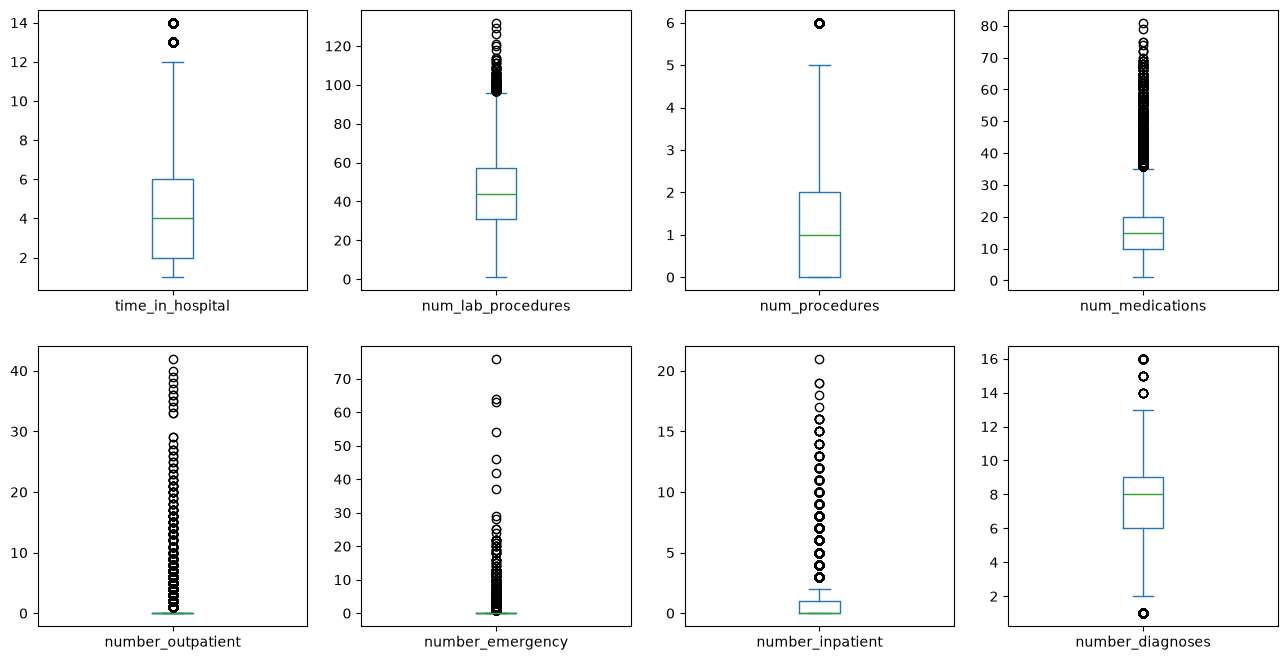

In [62]:
#Datensatz bereinigen (Ausschlusskriterien)
ausschluss_id = [    # alle ids der Ausschlusskriterien sammeln
    11, 19, 20, 21,  # Verstorben
    9, 12,           # Kein eindeutig abgeschlossener Aufenthalt
    13, 14,          # Hospiz
    18, 25, 26       # Entlassungsart unklar
]

#in den finalen Datensatz nur jene Einträge aufnehmen die nicht in den Ausschlusskriterien vorkommen und die discharge_disposition_id nicht leer ist
diabetes = diabetes_orig.loc[
    ~diabetes_orig["discharge_disposition_id"].isin(ausschluss_id) # ~ -> Negation, d.h. alle Einträge mit diesen IDs werden ausgeschlossen
    & diabetes_orig["discharge_disposition_id"].notna()         
]

#Kontrolle der Klassenverteilung der Outcomevariable
display(diabetes["readmitted"].value_counts())  #normalize=True -> relative Häufigkeiten anzeigen

#Anzahl der Einträge vor und nach der Bereinigung
print("Aufenthalte vorher:", len(diabetes_orig))
print("Aufenthalte danach:", len(diabetes))
print("Ausgeschlossen:", len(diabetes_orig) - len(diabetes))

#Datensatz in nummerische und kategrosiche Variablen einordnen
numeric_var = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

#kategorisch sind nur jene variablen die im diabtes Datensatz sind und nicht in den nummerischen vorkommen oder eines dieser Variablen sind [...]
categoric_var = [
    column for column in diabetes_orig.columns           
    if column not in numeric_var
    + ["encounter_id", "patient_nbr", "readmitted"]     #readmitted ist OUtcome Variable
]

#Verteilung der nummerischen und kategrosichen Variablen
display(diabetes_orig[numeric_var].describe())

#Verteilung der nummerischen AVriablen als Boxplot darstellen
diabetes_orig[numeric_var].plot(
    kind="box",
    subplots=True,
    layout=(2, 4),
    figsize=(16, 8),
    sharey=False
)

display(diabetes_orig[categoric_var].astype("category").describe())

**Interpretation der Verteilung:**  
Die Verteilungen der numerischen Variablen wurden anhand von Boxplots untersucht. Dabei zeigen mehrere Merkmale potenzielle Ausreißer. Insbesondere bei number_outpatient und num_medications fallen hohe Werte auf.
Laut Datensatzbeschreibung erfasst number_outpatient die Anzahl ambulanter Besuche im gesamten Jahr vor dem jeweiligen Krankenhausaufenthalt. Hohe Werte können daher beispielsweise bei Patienten mit regelmäßigem Behandlungsbedarf grundsätzlich plausibel sein. num_medications beschreibt die Anzahl unterschiedlicher generischer Medikamentenbezeichnungen, die während des gesamten Aufenthalts verabreicht wurden. Die Variable gibt somit weder die Anzahl einzelner Tabletten noch die Anzahl gleichzeitig eingenommener Medikamente an. 
Die auffälligen Werte werden zunächst beibehalten, da ihre Höhe allein keinen Datenfehler belegt und sie als plusibel eingestuft werden. Ihre tatsächliche Richtigkeit lässt sich anhand der verfügbaren Angaben jedoch nicht abschließend bestätigen.
Bei den kategorialen Merkmalen ist die Altersgruppe 70–80 Jahre am häufigsten vertreten. Die Medikamentenvariablen examide und citoglipton enthalten im untersuchten Datensatz ausschließlich die Kategorie „No“ und liefern somit keine Information zur Unterscheidung der Aufenthalte.


In [63]:

#Outcomevariable in binäre Variable mappen
target_var = diabetes["readmitted"].map({"NO": 0, 
                                         ">30": 0, 
                                         "<30": 1}) 

#Ausgabe der Klassenverteilung in einem DataFrame
class_distr = pd.DataFrame({"Anzahl": target_var.value_counts(),
                            "Anteil (%)": target_var.value_counts(normalize=True) * 100})

display(class_distr.round(2))  #Ausgabe und auf 2 Nachkommastellen runden

,Anzahl,Anteil (%)
readmitted,,
0,83887,88.64
1,10752,11.36


Nach Anwendung der Ausschlusskriterien verbleiben 94.639 von ursprünglich 101.766 Aufenthalten. Davon weisen 10.752 Aufenthalte (11,36 %) eine frühe Wiederaufnahme (<30 Tagen) auf. Die übrigen 83.887 Aufenthalte (88,64 %) gehören zur negativen Klasse (>30 Tage oder keine Wiederaufnahme). Es besteht somit ein deutliches Klassenungleichgewicht. Für den späteren Modellvergleich reicht die Accuracy allein daher nicht aus: Ein Modell, das ausschließlich die negative Klasse vorhersagt, würde bereits eine Accuracy von 88,64 % erreichen, ohne eine einzige frühe Wiederaufnahme zu erkennen. Deshalb werden zusätzlich die AUROC, die Sensitivität – der Anteil tatsächlich früher Wiederaufnahmen, die korrekt erkannt werden – sowie die Konfusionsmatrix betrachtet.

#### 2b Aufenthalte vs Patienten
Da wie bereits zuvor erwähnt ein Patient öfters im Datensatz vorkommen kann aufgrund von mehreren Aufenthalten wird im nächsten Schritt die Anzahl der Krankenhausaufenthlte die zum selben Pateinten gehören ermittelt.

In [64]:
#Anzahl der Aufenthalte pro Patient
display(diabetes.groupby("patient_nbr").size().reset_index(name="Anzahl Aufenthalte")) #.sort_values(by="Anzahl Aufenthalte", ascending=False)   .discribe()

print("Anzahl Aufenthalte:", len(diabetes))
print("Anzahl der Patienten:", diabetes["patient_nbr"].nunique())

#wie viele Patienten jeweils wie viele Aufenthalte haben:
display(diabetes.groupby("patient_nbr").size().value_counts())

,patient_nbr,Anzahl Aufenthalte
0,135,2
1,378,1
2,729,1
3,774,1
4,927,1
...,...,...
67303,189351095,1
67304,189365864,1
67305,189445127,1
67306,189481478,1


Anzahl Aufenthalte: 94639
Anzahl der Patienten: 67308


1     51949
2      9669
3      3042
4      1250
5       630
6       309
7       173
8       101
9        60
10       37
11       21
12       17
13       13
15        7
20        6
18        5
17        4
14        3
16        3
21        2
23        2
19        2
28        1
22        1
40        1
Name: count, dtype: int64

Da einzelne Patienten mehrere Krankenhausaufenthalte aufweisen, erfolgt die Aufteilung in Trainings-, Validierungs- und Testdaten gruppiert nach der patient_nbr, sodass alle Aufenthalte eines Patienten ausschließlich einem Teilset zugeordnet werden. Ohne patientenweise Aufteilung könnten Aufenthalte derselben Person in mehreren Teilsets vorkommen, wodurch die Vorhersage aufgrund wiederkehrender ähnlicher Merkmale positiver ausfallen könnte.

#### 2c Missing Values
Im nächsten Schritt wird auf die fehlenden Werte im Datensatz rücksicht genommen. Hierbei werden vor allem die drei Variablen weight, medical_specialty und payer_code beobachtet. Diese werden jeweils in einer Tabelle mit der Anzahl der fehldenden Werte und dem Prozentuellen anteil ausgegeben. Ebenso werden überlegungen angestellt warum es zu fehlenden Werten in diesen Bereichen kommen konnte

In [65]:
#Anzahl und prozentuellen anteil missingValues der Spalte weight, medical_specialty, payer_code ausgeben
missing_values = pd.DataFrame({"Anzahl missing Values": diabetes[["weight", "medical_specialty", "payer_code", "max_glu_serum", "A1Cresult"]].isna().sum()})
missing_values["Prozentueller Anteil"] = (missing_values["Anzahl missing Values"] / len(diabetes) * 100).round(2)
display(missing_values)


,Anzahl missing Values,Prozentueller Anteil
weight,91546,96.73
medical_specialty,45618,48.20
payer_code,34735,36.70
max_glu_serum,89842,94.93
A1Cresult,78632,83.09


Betrachtet man den prozentuellen Anteil der missing Values kommen wir auf folgende Schlussfolgerungen:  
Bei **weight** fehlen im ursprünglichen Datensatz knapp 97 % der Gewichte. Laut der Informationen aus dem Paper mussten Krankenhäuser das Gewicht vor der HITECH-Gesetzgebung 2009 nicht verpflichtend in strukturierter Form erfassen. Wir entschieden uns gleich wie die Autoren die Variable aufgrund ihrer geringen Anzahl an vorhanden Gewichten zu entfernen. Eine Imputation würde nahezu die gesamte Spalte betreffen und überwiegend auf Annahmen beruhen.  

Die Variable **medical_specialty** beschreibt laut Datensatzbeschreibung die Fachrichtung des aufnehmenden Arztes. Die Fachrichtung kann Hinweise auf die Station des Patienten und den Versorgungskontet geben und wird daher nicht verworfen. Eine Entfernung der gesamten Spalte würde vorhandene Informationen verwerfen; ein Ausschluss aller betroffenen Aufenthalte würde die verfügbare Datenmenge auf knapp 50% reduzieren. Daher wird eine zusätzliche Kategorie IS_MISSING eingeführt, um fehlende Angaben explizit abzubilden und gleichzeitig alle Aufenthalte zu erhalten.   

Im Gegensatz zu den Autoren behalten wir die Variable **payer_code** bei. Wir vermuten, dass die Art der Krankenversicherung mit dem Zugang zu medizinischer Versorgung und damit auch mit der Wahrscheinlichkeit einer erneuten Krankenhausaufnahme zusammenhängen könnte. Dieser Zusammenhang wird zunächst als mögliche Vorhersageinformation angenommen und ist durch unsere Analyse jedoch nicht belegt. Fehlende Angaben werden als eigene Kategorie IS_MISSING erfasst.  

Die soeben erwähnten Anpassungen werden im folgenden umgesetzt:

In [ ]:
#drop Colum weight
diabetes.drop(columns=["weight"])

#fehlende Fachrichtung und Versicherung als "IS_MISSING" eintragen
diabetes["medical_specialty"] = diabetes["medical_specialty"].fillna("IS_MISSING")
diabetes["payer_code"] = diabetes["payer_code"].fillna("IS_MISSING")

#### 2d Zielpopulation ermitteln
Der 4. Punkt der 2. Aufgabe wurde bereits umgesetzt indem die Entlassungsarten mithilfe des IDS_mapping.csv analysiert wurden. Insgesamt wurden hier 7127 Aufenthalte entfernt; die untersuchte Population umfasst damit 94.639 Aufenthalte. Eine genauere Erläuterung diesbezüglich ist in Aufgabe 1 'Problem Formulation' nachzulesen.

#### 2e ICD-9 Code Gruppierung
Die ICD-9-Codes weisen eine hohe Anzahl unterschiedlicher Kategorien auf. Deshalb werden sie anhand eines einheitlichen, klinisch begründeten Schemas zu übergeordneten Diagnosegruppen zusammengefasst. Dies reduziert die Anzahl seltener Kategorien und ermöglicht eine übersichtlichere Verarbeitung der Diagnoseinformationen.

In [66]:
#Häufigkeit von diagnoses in den Spalten diag_1, diag_2, diag_3
diagnoses = pd.concat([diabetes["diag_1"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten hauptdiagnosen
diagnoses = pd.concat([diabetes["diag_2"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten Nebendiagnosen
diagnoses = pd.concat([diabetes["diag_3"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten weiteren hauptdiagnosen


diagnoses_cols = ["diag_1", "diag_2", "diag_3"]

display(pd.DataFrame({
    "Unterschiedliche ICD-9-Codes": diabetes[diagnoses_cols].nunique(),
    "Fehlende Codes": diabetes[diagnoses_cols].isna().sum()
}))

diag_1
428      6289
414      6051
786      3751
486      3256
410      3176
427      2605
491      2167
715      2042
682      1941
780      1899
996      1844
434      1838
276      1758
250.8    1605
599      1527
38       1463
584      1415
250.6    1138
V57      1077
820      1024
Name: count, dtype: int64

diag_2
276       6383
428       6080
250       5713
427       4657
401       3515
599       3099
496       3058
403       2643
414       2453
411       2376
250.02    1989
707       1862
585       1744
584       1512
285       1462
491       1460
250.01    1387
780       1367
682       1358
425       1316
Name: count, dtype: int64

diag_3
250       10832
401        7753
276        4822
428        4205
427        3621
414        3414
496        2366
403        2201
272        1881
585        1848
599        1791
250.02     1291
V45        1289
707        1245
780        1238
285        1144
425        1057
250.6      1016
424        1004
305         876
Name: count, dtype: int64

,Unterschiedliche ICD-9-Codes,Fehlende Codes
diag_1,712,18
diag_2,742,343
diag_3,782,1339


Im ersten Schritt wurde ein Überblick über die Diagnosedaten erstellt. Dazu wurden für jede der drei Diagnosespalten die 20 häufigsten Codes sowie die Anzahl unterschiedlicher und fehlender Diagnosecodes ermittelt.
Aufgrund der hohen Anzahl unterschiedlicher Codes wurde ein bereits vorhandenes Gruppierungsschma gewählt. Als Grundlage dient die Einteilung aus Table 2 der Originalpublikation. Die Autoren fassen dort die Hauptdiagnosen zu übergeordneten Krankheitsgruppen zusammen. Diagnosegruppen, die jeweils weniger als 3,5 % der untersuchten Aufenthalte ausmachen, werden unter „Sonstiges“ zusammengefasst.

Für die Zuteilung der ICD-9-Codes wird eine Funktion definiert und auf allen drei Spalten angewendet.

In [ ]:
#Funktion zur Kategorisierung der Diagnosen
def get_diag_group(diag_code):
    #überprüfen ob code leer ist
    if pd.isna(diag_code):
        return "Fehlender Code"

    #wenn nciht dann code als string und leerzeichen entfernen (und in Großbuchstaben umwandeln) für Einheitliche abfragen
    diag_code = str(diag_code).strip().upper()

    #Codes mit E und V der Gruppe Sonstiges zuteilen
    if diag_code.startswith("V") or diag_code.startswith("E"):
        return "Sonstige"

    #Hauptcode bestimmen (nur 250 statt 250.13) -> ist selbe Kategorie
    try :
        icd9_code = int(diag_code.split(".")[0])  #nur der Hauptcode (vor dem Punkt)
    except ValueError:
        return "Fehlerhafter Code"

    #Zuteilung zu Gruppe abhängig vom "Hauptcode"
    if 390 <= icd9_code <= 459 or icd9_code == 785:
        return "Kreislauferkrankungen"
    elif 460 <= icd9_code <= 519 or icd9_code == 786:
        return "Atmungserkrankungen"
    elif 520 <= icd9_code <= 579 or icd9_code == 787:
        return "Verdauungserkrankungen"
    elif icd9_code ==250:
        return "Diabetes"
    elif 800 <= icd9_code <= 999:
        return "Verletzungen"
    elif 710 <= icd9_code <= 739:
        return "Muskuloskeletterkrankungen"
    elif 580 <= icd9_code <= 629 or icd9_code == 788:
        return "Genitourinäre Erkrankungen"
    elif 140 <= icd9_code <= 239:
        return "Neoplasmen" 
    else:
        return "Sonstige"


#Ergebnis in neuen Spalten speichern
for col in diagnoses_cols:
    diabetes[f"{col}_group"] = diabetes[col].apply(get_diag_group)      #diag_code ist Inhalt der aktuellen Zeile von col #.apply übergibt jeden Wert dieser Spalte einzeln an die Funktion.


#Kontrolle der Kategorisierung der Diagnosen anzeigen (Anzeigen der beiden zusammengehörigen relevanten Spalten mit ersten 10 Datensätzen)
display(diabetes[
    ["diag_1", "diag_1_group",
     "diag_2", "diag_2_group",
     "diag_3", "diag_3_group"]
].head(10))

#Anzahl der jeweiligen Diagnosen in der jeweiligen Gruppe (auswahl der Spalte)
for col in ["diag_1_group", "diag_2_group", "diag_3_group"]:
    display(diabetes[col].value_counts())

,diag_1,diag_1_group,diag_2,diag_2_group,diag_3,diag_3_group
1,276,Sonstige,250.01,Diabetes,255,Sonstige
2,648,Sonstige,250,Diabetes,V27,Sonstige
3,8,Sonstige,250.43,Diabetes,403,Kreislauferkrankungen
4,197,Neoplasmen,157,Neoplasmen,250,Diabetes
5,414,Kreislauferkrankungen,411,Kreislauferkrankungen,250,Diabetes
6,414,Kreislauferkrankungen,411,Kreislauferkrankungen,V45,Sonstige
7,428,Kreislauferkrankungen,492,Atmungserkrankungen,250,Diabetes
8,398,Kreislauferkrankungen,427,Kreislauferkrankungen,38,Sonstige
9,434,Kreislauferkrankungen,198,Neoplasmen,486,Atmungserkrankungen
10,250.7,Diabetes,403,Kreislauferkrankungen,996,Verletzungen


diag_1_group


diag_1_group
Kreislauferkrankungen         27927
Sonstige                      17065
Atmungserkrankungen           13324
Verdauungserkrankungen         8967
Diabetes                       8265
Verletzungen                   6558
Genitourinäre Erkrankungen     4837
Muskuloskeletterkrankungen     4695
Neoplasmen                     2983
Fehlender Code                   18
Name: count, dtype: int64

diag_2_group


diag_2_group
Kreislauferkrankungen         29466
Sonstige                      25037
Diabetes                      11926
Atmungserkrankungen            9919
Genitourinäre Erkrankungen     7852
Verdauungserkrankungen         3904
Verletzungen                   2274
Neoplasmen                     2237
Muskuloskeletterkrankungen     1681
Fehlender Code                  343
Name: count, dtype: int64

diag_3_group


diag_3_group
Kreislauferkrankungen         28116
Sonstige                      27432
Diabetes                      15988
Atmungserkrankungen            6691
Genitourinäre Erkrankungen     6171
Verdauungserkrankungen         3679
Muskuloskeletterkrankungen     1815
Verletzungen                   1814
Neoplasmen                     1594
Fehlender Code                 1339
Name: count, dtype: int64

Durch die Gruppierung der einzelnen ICD-9-Codes konnte die Anzahl der unterschiedlichen Diagnosen, die je nach Diagnosefeld zwischen 712 und 782 lag, auf neun übergeordnete Krankheitsgruppen reduziert werden. Dabei wurden Hauptdiagnosen, Nebendiagnosen und weitere Nebendiagnosen jeweils separat gruppiert und in neuen Spalten gespeichert.

Der Vergleich der drei resultierenden Diagnosegruppen zeigt, dass Herzerkrankungen sowohl bei den Hauptdiagnosen als auch bei den Nebendiagnosen am häufigsten vorkommen, gefolgt von der Gruppe „Sonstige Diagnosen“. Bei den Nebendiagnosen und den weiteren Nebendiagnosen steht Diabetes jeweils an dritter Stelle.

Auffällig ist außerdem, dass lediglich 18 Fälle keine dokumentierte Hauptdiagnose aufweisen. Die Anzahl der fehlenden Diagnosecodes nimmt hingegen von den Hauptdiagnosen über die Nebendiagnosen bis zu den weiteren Nebendiagnosen zu. Dies könnte darauf hindeuten, dass insbesondere zusätzliche Diagnosen nicht immer vollständig dokumentiert wurden, beispielsweise aufgrund von Unterschieden in der Dokumentationspraxis oder im klinischen Alltag. Die tatsächlichen Ursachen für die fehlenden Angaben lassen sich aus den vorliegenden Daten jedoch nicht eindeutig ableiten.